# GRN recovery benchmarking for hematopoiesis

Here, we compare the gene regulatory networks for the 4 synthetic curated datasets (10 different versions of each dataset) from BEELINE ([Pratapa et al. (2020)](https://doi.org/10.1038/s41592-019-0690-6)), recovered with bowside, GRNBoost2, or GENIE3.
As ground truth, we use the curated networks from BEELINE.
We compute the ROC and precision-recall curves and the area under the curve.
As a random baseline for comparison, we assign random ranks to a number of edges equivalent to the respective ground truth.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from bowside.dataset import PseudotimeDataset
from matplotlib import pyplot as plt
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    roc_auc_score,
    roc_curve,
)

In [2]:
# Load the data and construct PseudotimeDatasets
dataset_names = ["GSD", "HSC", "mCAD", "VSC"]
adatas = {
    name: sc.read_h5ad(
        f"../data/BEELINE-data/processed/Curated/{name}/{name}_processed_1.h5ad"
    )
    for name in dataset_names
}
datasets = {
    name: PseudotimeDataset(
        adata,
        layer="log1p",
        mask_var=None,
        pseudotime_key="pseudotime",
        num_cells=200,
    )
    for name, adata in adatas.items()
}

In [3]:
# Load the ground truth network
adj_lists_true = {
    name: pd.read_csv(
        f"../data/BEELINE-data/processed/Curated/{name}/{name}_adj_list.csv",
        index_col=0,
    )
    for name in dataset_names
}

In [4]:
def binary_adjacency_matrix(
    adj_list: pd.DataFrame,
    dataset: PseudotimeDataset,
    source_name: str = "Gene1",
    target_name: str = "Gene2",
):
    adjacency_matrix = pd.crosstab(adj_list[source_name], adj_list[target_name])
    return (
        adjacency_matrix.reindex(
            index=dataset.gene_names,
            columns=dataset.gene_names,
            fill_value=0,
        )
        .clip(upper=1)
        .astype(np.int8)
    )

In [5]:
# Construct binary ground truth adjacency matrices
adj_matrices_true = {
    name: binary_adjacency_matrix(adj_list, datasets[name])
    for name, adj_list in adj_lists_true.items()
}

In [6]:
# Load GRN inference results
n_runs = 10
grn_results = {
    name: {
        "GRNBoost2": [
            pd.read_parquet(f"../output/BEELINE_{name}/grnboost2/grn_res_{i}.parquet")
            for i in range(n_runs)
        ],
        "GENIE3": [
            pd.read_parquet(f"../output/BEELINE_{name}/genie3/grn_res_{i}.parquet")
            for i in range(n_runs)
        ],
        "bowside": [
            pd.DataFrame(
                np.load(
                    f"../output/BEELINE_{name}/bowside_optimized/model_{i}/adj_mat.npy"
                ),
                index=datasets[name].gene_names,
                columns=datasets[name].gene_names,
            )
            for i in range(n_runs)
        ],
    }
    for name in dataset_names
}

In [7]:
# Add missing rows for GRNBoost2 and GENIE3
for method in ["GRNBoost2", "GENIE3"]:
    for name, res_dict in grn_results.items():
        for i, res in enumerate(res_dict[method]):
            lines_to_append = []
            for source, target in pd.MultiIndex.from_product(
                [datasets[name].gene_names, datasets[name].gene_names]
            ):
                if len(res[(res["TF"] == source) & (res["target"] == target)]) == 0:
                    lines_to_append.append(
                        {"TF": source, "target": target, "importance": 0.0}
                    )
            df_to_append = pd.DataFrame(lines_to_append)
            res_dict[method][i] = pd.concat([res, df_to_append])

In [8]:
# Turn true adjacency matrix into pandas Series of true binary labels
adj_matrices_true_long = {
    name: adj_matrix.rename_axis(index="source", columns="target")
    .stack()
    .astype(np.int8)
    for name, adj_matrix in adj_matrices_true.items()
}

In [9]:
# Format GRN inference results as pandas Series of scores
grn_results_scores = {}
for name, res_dict in grn_results.items():
    grn_results_scores[name] = {}
    grn_results_scores[name]["GRNBoost2"] = [
        res.rename(columns={"TF": "source"})
        .set_index(["source", "target"])
        .loc[adj_matrices_true_long[name].index, :]
        for res in res_dict["GRNBoost2"]
    ]
    grn_results_scores[name]["GENIE3"] = [
        res.rename(columns={"TF": "source"})
        .set_index(["source", "target"])
        .loc[adj_matrices_true_long[name].index, :]
        for res in res_dict["GENIE3"]
    ]
    grn_results_scores[name]["bowside"] = [
        adj.rename_axis(index="source", columns="target").stack().abs()
        for adj in res_dict["bowside"]
    ]

In [10]:
# Generate random baselines
rng = np.random.default_rng(42)
for name, dataset in datasets.items():
    n_edges_true = adj_matrices_true_long[name].sum()
    grn_results_scores[name]["random"] = []
    for _ in range(n_runs):
        baseline = rng.permutation(dataset.n_genes() ** 2)
        baseline[baseline < (dataset.n_genes() ** 2 - n_edges_true)] = 0
        assert (baseline > 0).sum() == n_edges_true
        grn_results_scores[name]["random"].append(
            pd.Series(
                baseline,
                index=pd.MultiIndex.from_product(
                    [dataset.gene_names, dataset.gene_names]
                ),
            )
        )

In [11]:
# Compute ROC/PR curves and metrics for every method and run
curves = {}
metric_rows = []

for name, y_true_series in adj_matrices_true_long.items():
    y_true = y_true_series.to_numpy(dtype=np.int8)
    n_edges_true = y_true.sum()
    curves[name] = {}

    for method, runs in grn_results_scores[name].items():
        curves[name][method] = []

        for run, score_data in enumerate(runs):
            if isinstance(score_data, pd.DataFrame):
                y_score = score_data["importance"].to_numpy()
            else:
                y_score = score_data.to_numpy()

            fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
            precision, recall, pr_thresholds = precision_recall_curve(y_true, y_score)
            early_precision_threshold = sorted(y_score)[-n_edges_true]
            if early_precision_threshold == 0:
                # Use all predicted edges if they are fewer than in the truth
                y_pred = (y_score > early_precision_threshold).astype(int)
                assert n_edges_true > y_pred.sum()
            else:
                y_pred = (y_score >= early_precision_threshold).astype(int)
                assert n_edges_true == y_pred.sum()

            auroc = roc_auc_score(y_true, y_score)
            average_precision = average_precision_score(y_true, y_score)

            curves[name][method].append(
                {
                    "fpr": fpr,
                    "tpr": tpr,
                    "roc_thresholds": roc_thresholds,
                    "precision": precision,
                    "recall": recall,
                    "pr_thresholds": pr_thresholds,
                }
            )

            metric_rows.append(
                {
                    "method": method,
                    "run": run,
                    "dataset": name,
                    "auroc": auroc,
                    "average_precision": average_precision,
                    "early_precision": precision_score(y_true, y_pred),
                }
            )

metrics = pd.DataFrame(metric_rows)

display(metrics)
display(
    metrics.groupby(["method", "dataset"])[
        ["auroc", "average_precision", "early_precision"]
    ].agg(["mean", "std"])
)

,method,run,dataset,auroc,average_precision,early_precision
0,GRNBoost2,0,GSD,0.582997,0.294528,0.341772
1,GRNBoost2,1,GSD,0.569710,0.266938,0.316456
2,GRNBoost2,2,GSD,0.574603,0.289918,0.379747
3,GRNBoost2,3,GSD,0.609750,0.313204,0.367089
4,GRNBoost2,4,GSD,0.577161,0.269836,0.303797
...,...,...,...,...,...,...
155,random,5,VSC,0.451701,0.336458,0.133333
156,random,6,VSC,0.519728,0.253658,0.266667
157,random,7,VSC,0.533333,0.327431,0.266667
158,random,8,VSC,0.431293,0.224770,0.133333


auroc           average_precision            \
                       mean       std              mean       std   
method    dataset                                                   
GENIE3    GSD      0.600848  0.003098          0.282157  0.003599   
          HSC      0.699267  0.009736          0.452947  0.014459   
          VSC      0.831837  0.010064          0.745462  0.008726   
          mCAD     0.538312  0.004791          0.552738  0.003718   
GRNBoost2 GSD      0.594165  0.018429          0.296757  0.025648   
          HSC      0.618315  0.025652          0.373351  0.018030   
          VSC      0.806667  0.028477          0.618262  0.056336   
          mCAD     0.505844  0.037170          0.554763  0.051779   
bowside   GSD      0.556664  0.031745          0.240624  0.018151   
          HSC      0.689432  0.054586          0.444084  0.086906   
          VSC      0.743810  0.034912          0.524924  0.072376   
          mCAD     0.554221  0.055902          0.634132  0.050037   
random    GSD      0.489633  0.041368          0.229150  0.025432   
          HSC      0.517363  0.051552          0.282660  0.051722   
          VSC      0.494150  0.057665          0.273784  0.045784   
          mCAD     0.488312  0.076820          0.591026  0.050538   

                  early_precision            
                             mean       std  
method    dataset                            
GENIE3    GSD            0.336709  0.023264  
          HSC            0.466667  0.027217  
          VSC            0.666667  0.000000  
          mCAD           0.642857  0.000000  
GRNBoost2 GSD            0.332911  0.038695  
          HSC            0.343333  0.056765  
          VSC            0.566667  0.056656  
          mCAD           0.564286  0.022588  
bowside   GSD            0.243038  0.037645  
          HSC            0.446667  0.072350  
          VSC            0.533333  0.076980  
          mCAD           0.600000  0.036886  
random    GSD            0.201266  0.060398  
          HSC            0.276667  0.075441  
          VSC            0.220000  0.089166  
          mCAD           0.557143  0.065638

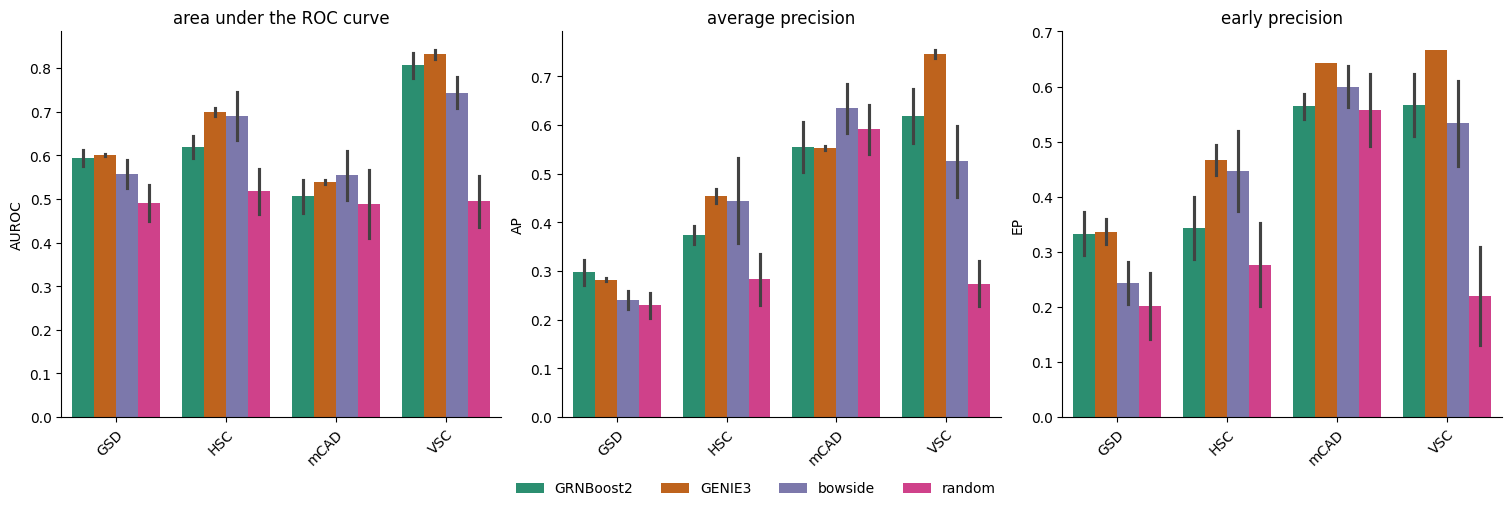

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
sns.barplot(
    metrics,
    x="dataset",
    y="auroc",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[0],
)
axs[0].set_title("area under the ROC curve")
axs[0].set_ylabel("AUROC")
sns.barplot(
    metrics,
    x="dataset",
    y="average_precision",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[1],
)
axs[1].set_title("average precision")
axs[1].set_ylabel("AP")
sns.barplot(
    metrics,
    x="dataset",
    y="early_precision",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[2],
)
axs[2].set_title("early precision")
axs[2].set_ylabel("EP")

handles, labels = axs[0].get_legend_handles_labels()
for ax in axs:
    ax.set_xticklabels(
        ax.get_xticklabels(), ha="right", rotation=45, rotation_mode="anchor"
    )
    ax.set_xlabel("")
    ax.get_legend().remove()
    ax.set_ylim(0, None)
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
sns.despine(fig)

In [13]:
OUTDIR = Path("../output/")
OUTDIR.mkdir(parents=True, exist_ok=True)
metrics.to_parquet(OUTDIR / "BEELINE_grn_benchmark_results.parquet")

# Save ROC and PR curves in long format (one row per curve point)
roc_curve_dfs = []
pr_curve_dfs = []
for name, method_curves in curves.items():
    for method, runs in method_curves.items():
        for run, run_curve in enumerate(runs):
            roc_curve_dfs.append(
                pd.DataFrame(
                    {
                        "dataset": name,
                        "method": method,
                        "run": run,
                        "fpr": run_curve["fpr"],
                        "tpr": run_curve["tpr"],
                        "threshold": run_curve["roc_thresholds"],
                    }
                )
            )
            # The last PR point (recall=0, precision=1) has no threshold
            pr_curve_dfs.append(
                pd.DataFrame(
                    {
                        "dataset": name,
                        "method": method,
                        "run": run,
                        "precision": run_curve["precision"],
                        "recall": run_curve["recall"],
                        "threshold": np.append(run_curve["pr_thresholds"], np.nan),
                    }
                )
            )

roc_curves = pd.concat(roc_curve_dfs, ignore_index=True)
pr_curves = pd.concat(pr_curve_dfs, ignore_index=True)
roc_curves.to_parquet(OUTDIR / "BEELINE_grn_benchmark_roc_curves.parquet")
pr_curves.to_parquet(OUTDIR / "BEELINE_grn_benchmark_pr_curves.parquet")

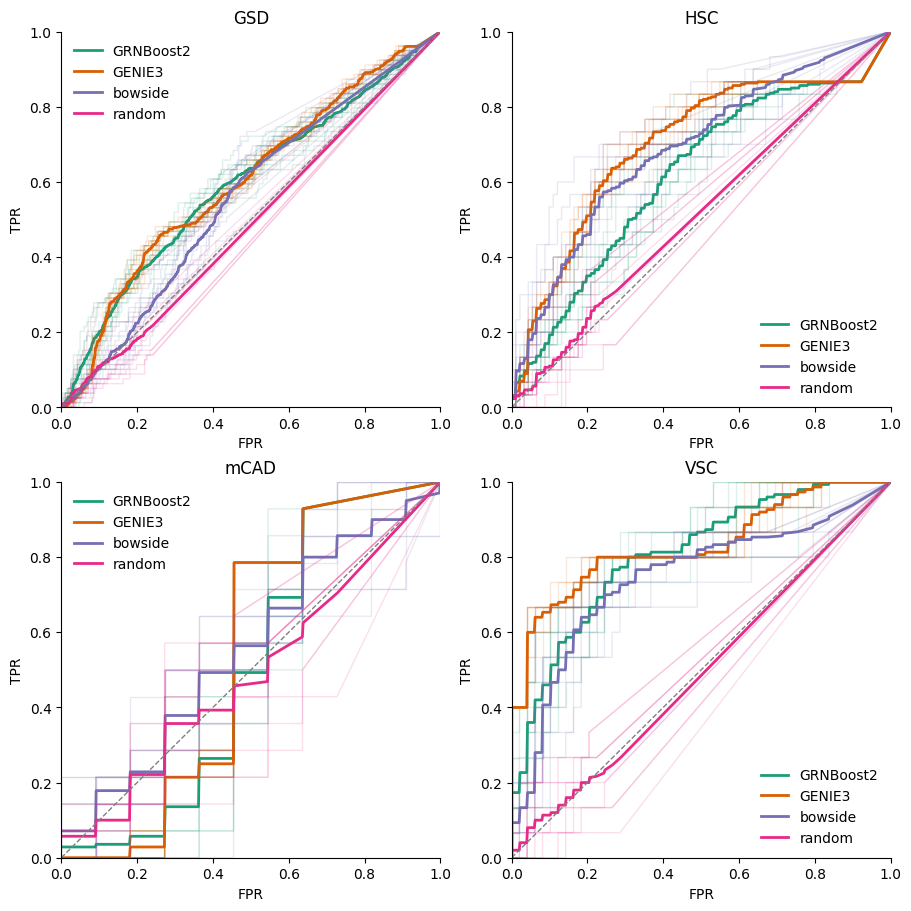

In [14]:
methods = list(curves[dataset_names[0]])
fpr_grid = np.linspace(0, 1, 501)

fig, axs = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
axs = axs.ravel()

colors = dict(zip(methods, sns.color_palette("Dark2", n_colors=len(methods))))

for ax, dataset_name in zip(axs, dataset_names):
    for method in methods:
        method_curves = curves[dataset_name][method]

        interpolated_tprs = []
        for run_curve in method_curves:
            fpr = run_curve["fpr"]
            tpr = run_curve["tpr"]

            ax.plot(
                fpr,
                tpr,
                color=colors[method],
                alpha=0.15,
                linewidth=1,
            )
            interpolated_tprs.append(np.interp(fpr_grid, fpr, tpr))

        mean_tpr = np.mean(interpolated_tprs, axis=0)
        ax.plot(
            fpr_grid,
            mean_tpr,
            color=colors[method],
            linewidth=2,
            label=method,
        )

    ax.plot(
        [0, 1],
        [0, 1],
        color="gray",
        linestyle="--",
        linewidth=1,
    )
    ax.set_title(dataset_name)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False)

sns.despine(fig)

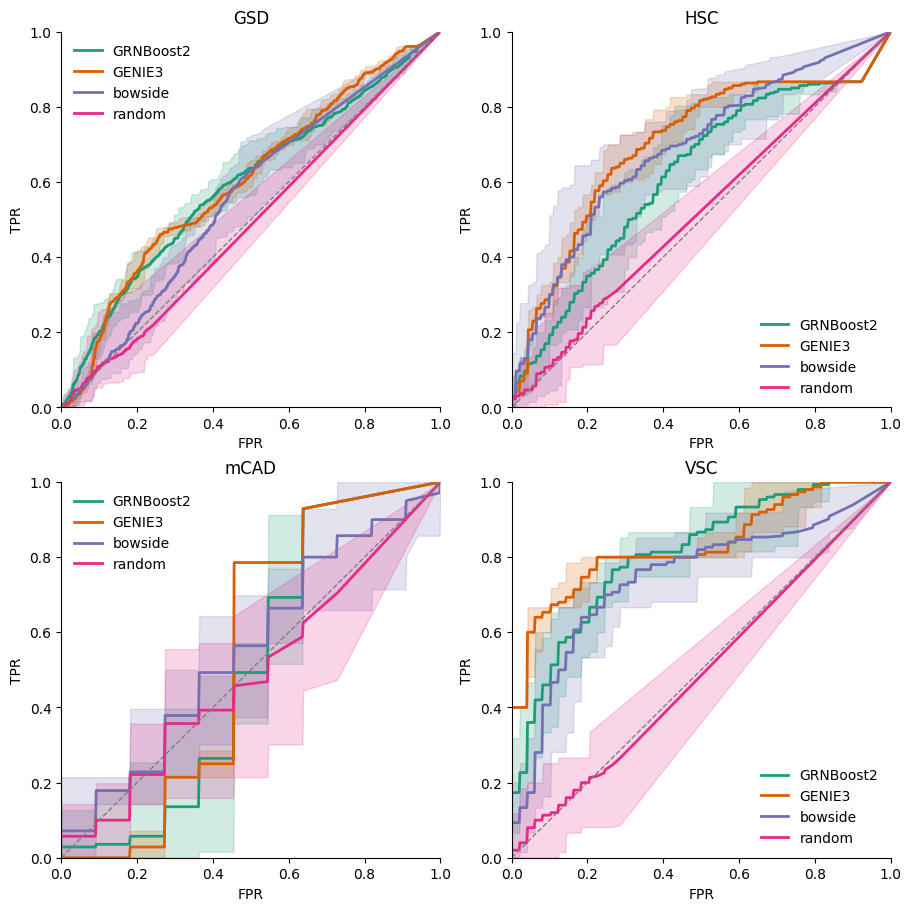

In [16]:
fpr_grid = np.linspace(0, 1, 501)

fig, axs = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
axs = axs.ravel()

colors = dict(zip(methods, sns.color_palette("Dark2", n_colors=len(methods))))

for ax, dataset_name in zip(axs, dataset_names):
    for method in methods:
        method_curves = curves[dataset_name][method]

        interpolated_tprs = np.array(
            [
                np.interp(fpr_grid, run_curve["fpr"], run_curve["tpr"])
                for run_curve in method_curves
            ]
        )

        mean_tpr = interpolated_tprs.mean(axis=0)
        lower_tpr, upper_tpr = np.percentile(interpolated_tprs, [2.5, 97.5], axis=0)

        ax.plot(
            fpr_grid,
            mean_tpr,
            color=colors[method],
            linewidth=2,
            label=method,
        )
        ax.fill_between(
            fpr_grid,
            lower_tpr,
            upper_tpr,
            color=colors[method],
            alpha=0.2,
        )

    ax.plot(
        [0, 1],
        [0, 1],
        color="gray",
        linestyle="--",
        linewidth=1,
    )
    ax.set_title(dataset_name)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False)

sns.despine(fig)

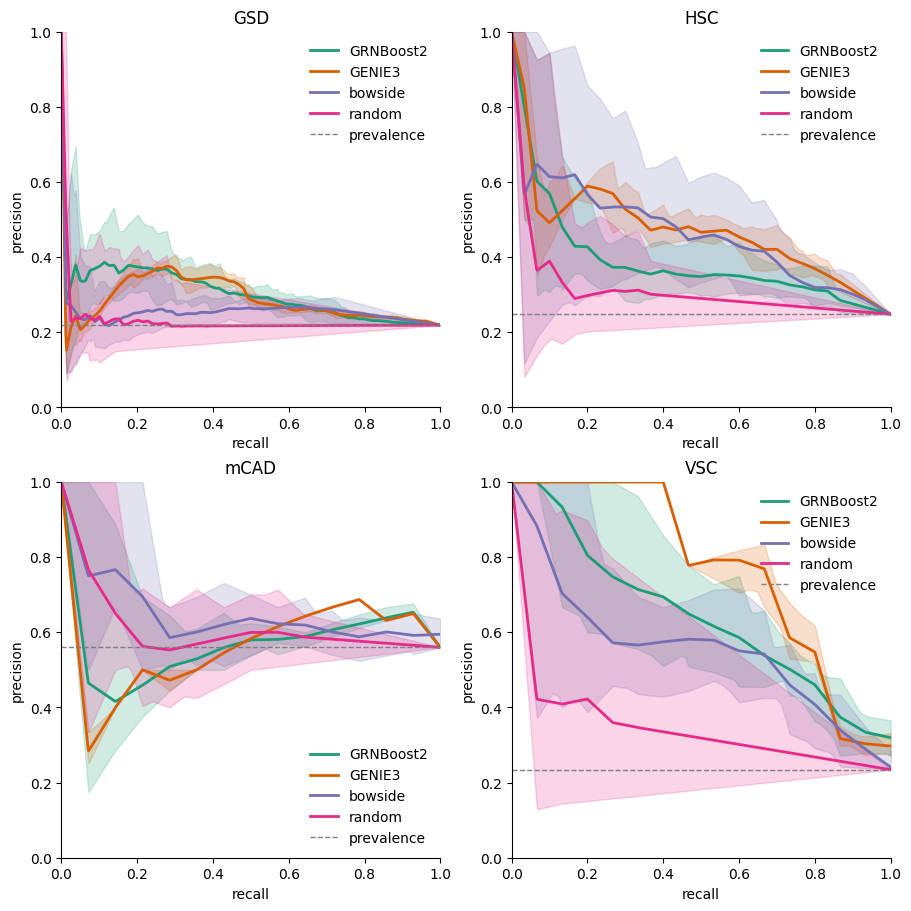

In [18]:
recall_grid = np.linspace(0, 1, 501)

fig, axs = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
axs = axs.ravel()

colors = dict(zip(methods, sns.color_palette("Dark2", n_colors=len(methods))))

for ax, dataset_name in zip(axs, dataset_names):
    y_true = adj_matrices_true_long[dataset_name].to_numpy()
    prevalence = y_true.mean()

    for method in methods:
        interpolated_precisions = []

        for run_curve in curves[dataset_name][method]:
            precision = run_curve["precision"]
            recall = run_curve["recall"]

            order = np.argsort(recall)
            recall_sorted = recall[order]
            precision_sorted = precision[order]

            recall_unique, inverse = np.unique(recall_sorted, return_inverse=True)
            precision_unique = np.full(recall_unique.shape, -np.inf)
            np.maximum.at(precision_unique, inverse, precision_sorted)

            interpolated_precisions.append(
                np.interp(recall_grid, recall_unique, precision_unique)
            )

        interpolated_precisions = np.array(interpolated_precisions)
        mean_precision = interpolated_precisions.mean(axis=0)
        lower_precision, upper_precision = np.percentile(
            interpolated_precisions, [2.5, 97.5], axis=0
        )

        ax.plot(
            recall_grid,
            mean_precision,
            color=colors[method],
            linewidth=2,
            label=method,
        )
        ax.fill_between(
            recall_grid,
            lower_precision,
            upper_precision,
            color=colors[method],
            alpha=0.2,
        )

    ax.axhline(
        prevalence,
        color="gray",
        linestyle="--",
        linewidth=1,
        label="prevalence",
    )
    ax.set_title(dataset_name)
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False)

sns.despine(fig)